# 1. Supervised learning: classification

Predict a **category** from labelled examples. Here a small decision tree learns whether synthetic fruit is ripe from colour and firmness. Features and labels are invented, not measurements.

**Setup:** Follow [README.md](README.md) to create a virtual environment,
install all packages and choose the `Python (AGR9027 ML)` kernel. Run all cells
in order. All observations here are artificial; ML is optional for Assessment 2.

Feature rows: [[0.77395605 0.43887844]
 [0.85859792 0.69736803]
 [0.09417735 0.97562235]] 
Labels (0 = unripe, 1 = ripe): [1 1 0]


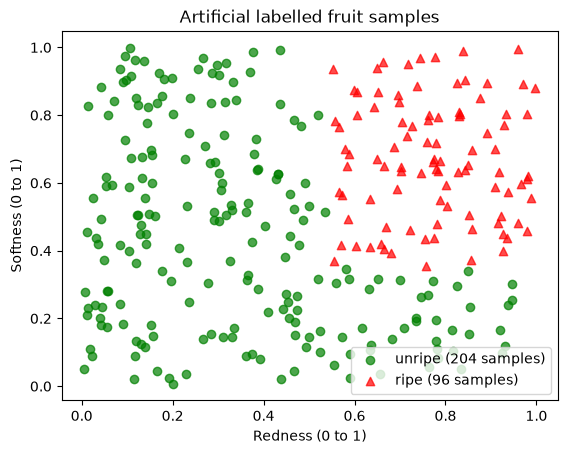

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import joblib
from tempfile import TemporaryDirectory
from pathlib import Path

rng = np.random.default_rng(42)
# Two artificial features per fruit, both between 0 and 1.
X = rng.uniform(0, 1, size=(300, 2))  # redness, softness
y = ((X[:, 0] > 0.55) & (X[:, 1] > 0.35)).astype(int)
print("Feature rows:", X[:3], "\nLabels (0 = unripe, 1 = ripe):", y[:3])

# Each point is one fruit; colour and marker indicate its known label.
for label, name, colour, marker in [(0, "unripe", "green", "o"),
                                    (1, "ripe", "red", "^")]:
    samples = X[y == label]
    plt.scatter(samples[:, 0], samples[:, 1], c=colour, marker=marker,
                alpha=0.7, label=f"{name} ({len(samples)} samples)")
plt.xlabel("Redness (0 to 1)")
plt.ylabel("Softness (0 to 1)")
plt.title("Artificial labelled fruit samples")
plt.legend()
plt.show()

## Split, train and evaluate

We split the labelled examples **before training**: 75% are used to fit the model and 25% are held out for testing. A model can learn the training examples without generalising, so testing on examples it did not learn from gives a more useful estimate of performance on new, similar data. `stratify=y` keeps the proportions of the two labels similar in each set, and `random_state=42` makes the split reproducible. Here the data are artificial, so the result does not establish accuracy on real fruit.

The **confusion matrix** compares the known test labels with the model's predictions. Rows are the true labels; columns are the predicted labels. Each number is the count of test samples in that combination:

| | Predicted unripe | Predicted ripe |
|---|---|---|
| **Actually unripe** | Correctly identified unripe | Unripe incorrectly predicted ripe (false positive for ripe) |
| **Actually ripe** | Ripe incorrectly predicted unripe (false negative for ripe) | Correctly identified ripe |

The diagonal contains correct predictions; the other two cells contain errors. **Accuracy** is the number of correct predictions divided by all test samples. Look at both types of error as well as accuracy, especially if one class is much more common than the other.

Test accuracy: 1.0


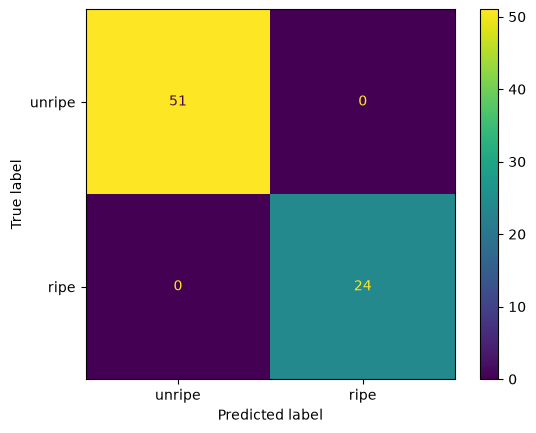

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)
predicted = model.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, predicted), 3))
ConfusionMatrixDisplay(confusion_matrix(y_test, predicted), display_labels=["unripe", "ripe"]).plot()
plt.show()

## Use and save the model

Features for new fruit must use the **same order and scale**. This temporary file shows saving and reloading; choose a permanent path if you need to transfer a model. Only load trusted joblib files.

In [6]:
new_fruit = np.array([[0.85, 0.65], [0.20, 0.40]])
with TemporaryDirectory() as folder:
    path = Path(folder) / "fruit_tree.joblib"
    joblib.dump(model, path)
    loaded_model = joblib.load(path)
    for features, label in zip(new_fruit, loaded_model.predict(new_fruit)):
        print(features, "->", "ripe" if label == 1 else "unripe")

[0.85 0.65] -> ripe
[0.2 0.4] -> unripe


**Try:** In the training cell, change `DecisionTreeClassifier(max_depth=3, random_state=42)` to use `max_depth=1`, then rerun that cell and the following cells. `max_depth` limits how many decision splits can occur along a path from the tree's root to a prediction: a depth of 1 allows only one split. A shallow tree may miss useful patterns (underfit); a deeper tree can represent more complex rules but may fit noise (overfit). Compare the test accuracy and confusion matrix, then try `max_depth=2` or `max_depth=5`. If you use test results to choose a model, evaluate the final choice on a separate, untouched test set. In a real project use independently collected labelled fruit images, inspect false positives and negatives, and test under changed lighting. A fruit-level classifier alone does not locate or count overlapping fruit.